# Distributed conditional training: workflow, evidence, and continuation

This tutorial follows the Phase K conditional-graph DDP campaign from the
distributed wrapper's API to the saved evidence. It reads the campaign
artifacts under `artifacts/logs/conditional-wrapper/` by default. **No GPU
allocation and no MPI launch are required to run the analysis.** The notebook
kernel parses files, calls the Python plotters through `uv`, and displays their
PNG output; it never joins a collective. Fresh training is available as an
opt-in child process through the bounded campaign driver.

The default configuration is the **four-rank Leonardo run** (4x A100,
CUDA/NCCL). Set `PHASE_K_TUTORIAL_CONFIG=tutorial-2rank` in the kernel
environment, or edit the configuration cell, to analyze the **two-rank
deathstar run** (2x TITAN RTX, CUDA/NCCL) instead. Both bundles share the same
prepared MNIST/Fashion-MNIST artifact, so the dataset identity selects the
head exactly as it did in the campaign.

Reading order:

1. Configuration and provenance.
2. Shared-trunk model and dataset-conditioned routing.
3. Six-step schedule and gradient weighting.
4. Backend initialization and the public `DistributedOptimizer` API.
5. Local AD followed by the distributed wrapper update outside AD.
6. Reference comparisons and the collective protocol.
7. Learning curves, configured learning rate, and predictions.
8. Data-only checkpoint and fresh-process continuation.
9. Reproduction commands, child-process training, and demonstrated scope.

Every figure section states its question, the data-derived observation, and
the interpretation. Raw maximum errors are reported separately from the
recorded `atol`/`rtol` acceptance result.

## 1. Configuration and provenance

The configuration cell selects a **complete run bundle**, not a rank-count
label: campaign root, config directory, rank count, backend, hardware, and the
shared prepared dataset. A missing required artifact raises an explicit error
that lists every missing path; no figure silently falls back to another run.

In [1]:
# Selection: "tutorial-4rank" (default, Leonardo 4x A100) or
# "tutorial-2rank" (deathstar 2x TITAN RTX). Both use CUDA/NCCL.
config_key = get(ENV, "PHASE_K_TUTORIAL_CONFIG", "tutorial-4rank")

# Figure regeneration calls the Python plotters through the pinned `uv`
# environment in scripts/plots/requirements-phase-k.txt. Fresh training is OFF
# by default; when enabled it runs the bounded driver as a child process.
regenerate_figures = true
run_training = false

include(joinpath(@__DIR__, "phase_k_workflow_helpers.jl"))
using .PhaseKWorkflow
using Printf

bundle = resolve_bundle(config_key)
println("repository root : ", REPO_ROOT)
println("configuration   : ", bundle.key, " (", bundle.description, ")")
println("campaign root   : ", bundle.run_root)
println("prepared root   : ", bundle.prepared)
println("kernel mode     : ", run_training ? "child-process training enabled" : "saved artifacts only")

repository root : /home/kurapica/Projects/ddp_flux/ddp-flux-thesis


configuration   : tutorial-2rank (deathstar, 2x TITAN RTX, CUDA/NCCL)
campaign root   : artifacts/logs/conditional-wrapper/demo/k2-2026-10-05-deathstar-nccl2
prepared root   : artifacts/logs/conditional-wrapper/demo/k2-2026-10-05-deathstar-mpi/prepared
kernel mode     : saved artifacts only


In [2]:
data = load_bundle(bundle)
bundle_overview(data)

field,value
selection,tutorial-2rank
description,"deathstar, 2x TITAN RTX, CUDA/NCCL"
campaign root,artifacts/logs/conditional-wrapper/demo/k2-2026-10-05-deathstar-nccl2
config / ranks,nccl2 / 2
backend / dtype,nccl / Float32
host / node,deathstar / gnode01
GPU devices,"NVIDIA TITAN RTX, devices [1, 2]"
Julia,1.12.6
Flux / Optimisers,0.16.11 / 0.4.9
MPI,0.20.27


**Observation.** The selected bundle is a recorded 120-step
MNIST/Fashion-MNIST NCCL campaign with global batch 128, native Adam
(`eta=0.001`), and the declared tolerances `atol=2.0e-6, rtol=1.0e-5`
(campaign status `PASS`). The rank count, local batch, hardware, device map,
and schedule digest are in the table above and follow the selected bundle.

**Interpretation.** The provenance table below ties the analysis to the
recorded software and data identity. The Flux wrapper sources still match the
current `../flux-integration` worktree. One stage script (`reference.jl`)
changed after the campaign: the corrected timing driver later added the plain
`reference_update!` helper. The K2 training path used `global_gradient` and
the demo checkpoint path is unaffected; the change is documented in
`reports/conditional-graph-phase-k-timing-stretch.md`. All other recorded
script and Flux hashes match.

In [3]:
prov = provenance_table(data)
display(prov.table)
println()
println("recorded source hashes matching the current worktree: ", prov.n_match, "/", prov.n_total)
flux_match = all(entry.match for entry in prov.entries if startswith(entry.rel, "flux-integration/"))
println("Flux wrapper sources matching ../flux-integration: ", flux_match)
for entry in prov.entries
    entry.match && continue
    println("changed after the campaign: ", entry.rel)
end

source,campaign SHA-256,current SHA-256,state
flux-integration/src/Flux.jl,78710f9b3989...,78710f9b3989...,match
flux-integration/src/distributed/public_api.jl,2984210b84e1...,2984210b84e1...,match
scripts/checks/conditionalgraphdemo_check.jl,2241cb6b1c37...,2241cb6b1c37...,match
scripts/examples/conditional_graph/checkpoint.jl,d494550fbdab...,d494550fbdab...,match
scripts/examples/conditional_graph/common.jl,9dfa74ee90c2...,9dfa74ee90c2...,match
scripts/examples/conditional_graph/dataset.jl,1681c7b7a505...,1681c7b7a505...,match
scripts/examples/conditional_graph/metrics.jl,74f25667fd48...,74f25667fd48...,match
scripts/examples/conditional_graph/model.jl,07de4f0fb5be...,07de4f0fb5be...,match
scripts/examples/conditional_graph/reference.jl,71ac4a90d377...,324c735ca9c8... (changed),changed
scripts/examples/conditional_graph/schedule.jl,9e7bb59e8494...,9e7bb59e8494...,match



recorded source hashes matching the current worktree: 10/11
Flux wrapper sources matching ../flux-integration: true


changed after the campaign: 

scripts/examples/conditional_graph/reference.jl


In [4]:
prepared_provenance_table(data)

prepared artifact field,value
loader,official-idx-gzip-v1; Julia Downloads; external gzip
preprocessing,IDX row-major flatten; Float32(byte)/255; no augmentation
label encoding,0:9; onehot row=label+1
task mapping,"(a = ""MNIST digits"", b = ""Fashion-MNIST clothing"")"
seeds,"(train = 101, val = 202, init = 303, order = 404, subset = 505)"
dataset digest,658e3dd341ca4e4fa9e5e4a05eacf53c0bebca626a05b17a87e917062dec2971
model definition,version 1
optimizer,"Adam eta=0.001 beta=(0.9, 0.999)"
prepared SHA-256 (recorded),7f0d38d997b14de3905ab9176cd3f914103363398c0bd9be6bf6360595373cd6
"schedule digest, 2 ranks",digest=f27e2ef87e10d9dfe63f99f62fad82d58db5d54309c9b621bcdbb8496e539280


In [5]:
artifact_inventory(data)

artifact,SHA-256
artifacts/logs/conditional-wrapper/demo/k2-2026-10-05-deathstar-nccl2/summary.txt,d78b4c3c0fe33652...
artifacts/logs/conditional-wrapper/demo/k2-2026-10-05-deathstar-nccl2/nccl2-train/console.log,c5152376bdb11122...
artifacts/logs/conditional-wrapper/demo/k2-2026-10-05-deathstar-nccl2/nccl2-resume/console.log,5b1d33ed06fcaf6f...
artifacts/logs/conditional-wrapper/demo/k2-2026-10-05-deathstar-nccl2/nccl2-train/command.txt,6eeb895595909008...
artifacts/logs/conditional-wrapper/demo/k2-2026-10-05-deathstar-nccl2/nccl2-resume/command.txt,ac3cf0cf1cc44cd5...
artifacts/logs/conditional-wrapper/demo/k2-2026-10-05-deathstar-mpi/prepared/prepare_metadata.txt,d2e11ab1b6f99713...
artifacts/logs/conditional-wrapper/demo/k2-2026-10-05-deathstar-mpi/prepared/sources.tsv,b6390a94ab739fce...
artifacts/logs/conditional-wrapper/demo/k2-2026-10-05-deathstar-mpi/prepared/subset_indices.tsv,1e59f762149a25a6...
artifacts/logs/conditional-wrapper/demo/k2-2026-10-05-deathstar-mpi/prepared/schedule-ranks2.tsv,40380efca9e86783...
artifacts/logs/conditional-wrapper/demo/k2-2026-10-05-deathstar-nccl2/nccl2/train/metadata.txt,a03234c58389e26e...


**Observation.** The inventory lists every loaded artifact with its SHA-256:
train and resume tables, metadata, command records, console logs, the
checkpoint and trajectory, and the shared prepared provenance.

**Interpretation.** The analysis is inspectable end to end. Table inputs are
parsed with exact header and field checks; a malformed row or duplicate key
stops the plotter with a schema error before any figure is written.

## 2. Shared-trunk model and dataset-conditioned routing

The model is a `TwoHeadModel`: a `Dense(784 => 32, tanh)` shared trunk and two
`Dense(32 => 10)` heads, 25,780 Float32 parameters in total. The **dataset
identity selects the head**: every sample carries its task label, and the
forward pass calls exactly one head. The target class never selects the head,
and no learned router is involved.

The six-step routing cycle repeats deterministically:

| Step | Routing |
|---|---|
| 1 | rank 0 task A, other ranks task B (local absence) |
| 2 | same split, after nonzero Adam history on both heads |
| 3 | all ranks task A (task B globally absent) |
| 4 | all ranks task B (task A globally absent) |
| 5 | same split as step 1 (reactivation after absence) |
| 6 | reversed split: rank 0 task B, others task A |

**Question.** What is the model, and how does the saved schedule realize the
six-step cycle at this rank count?

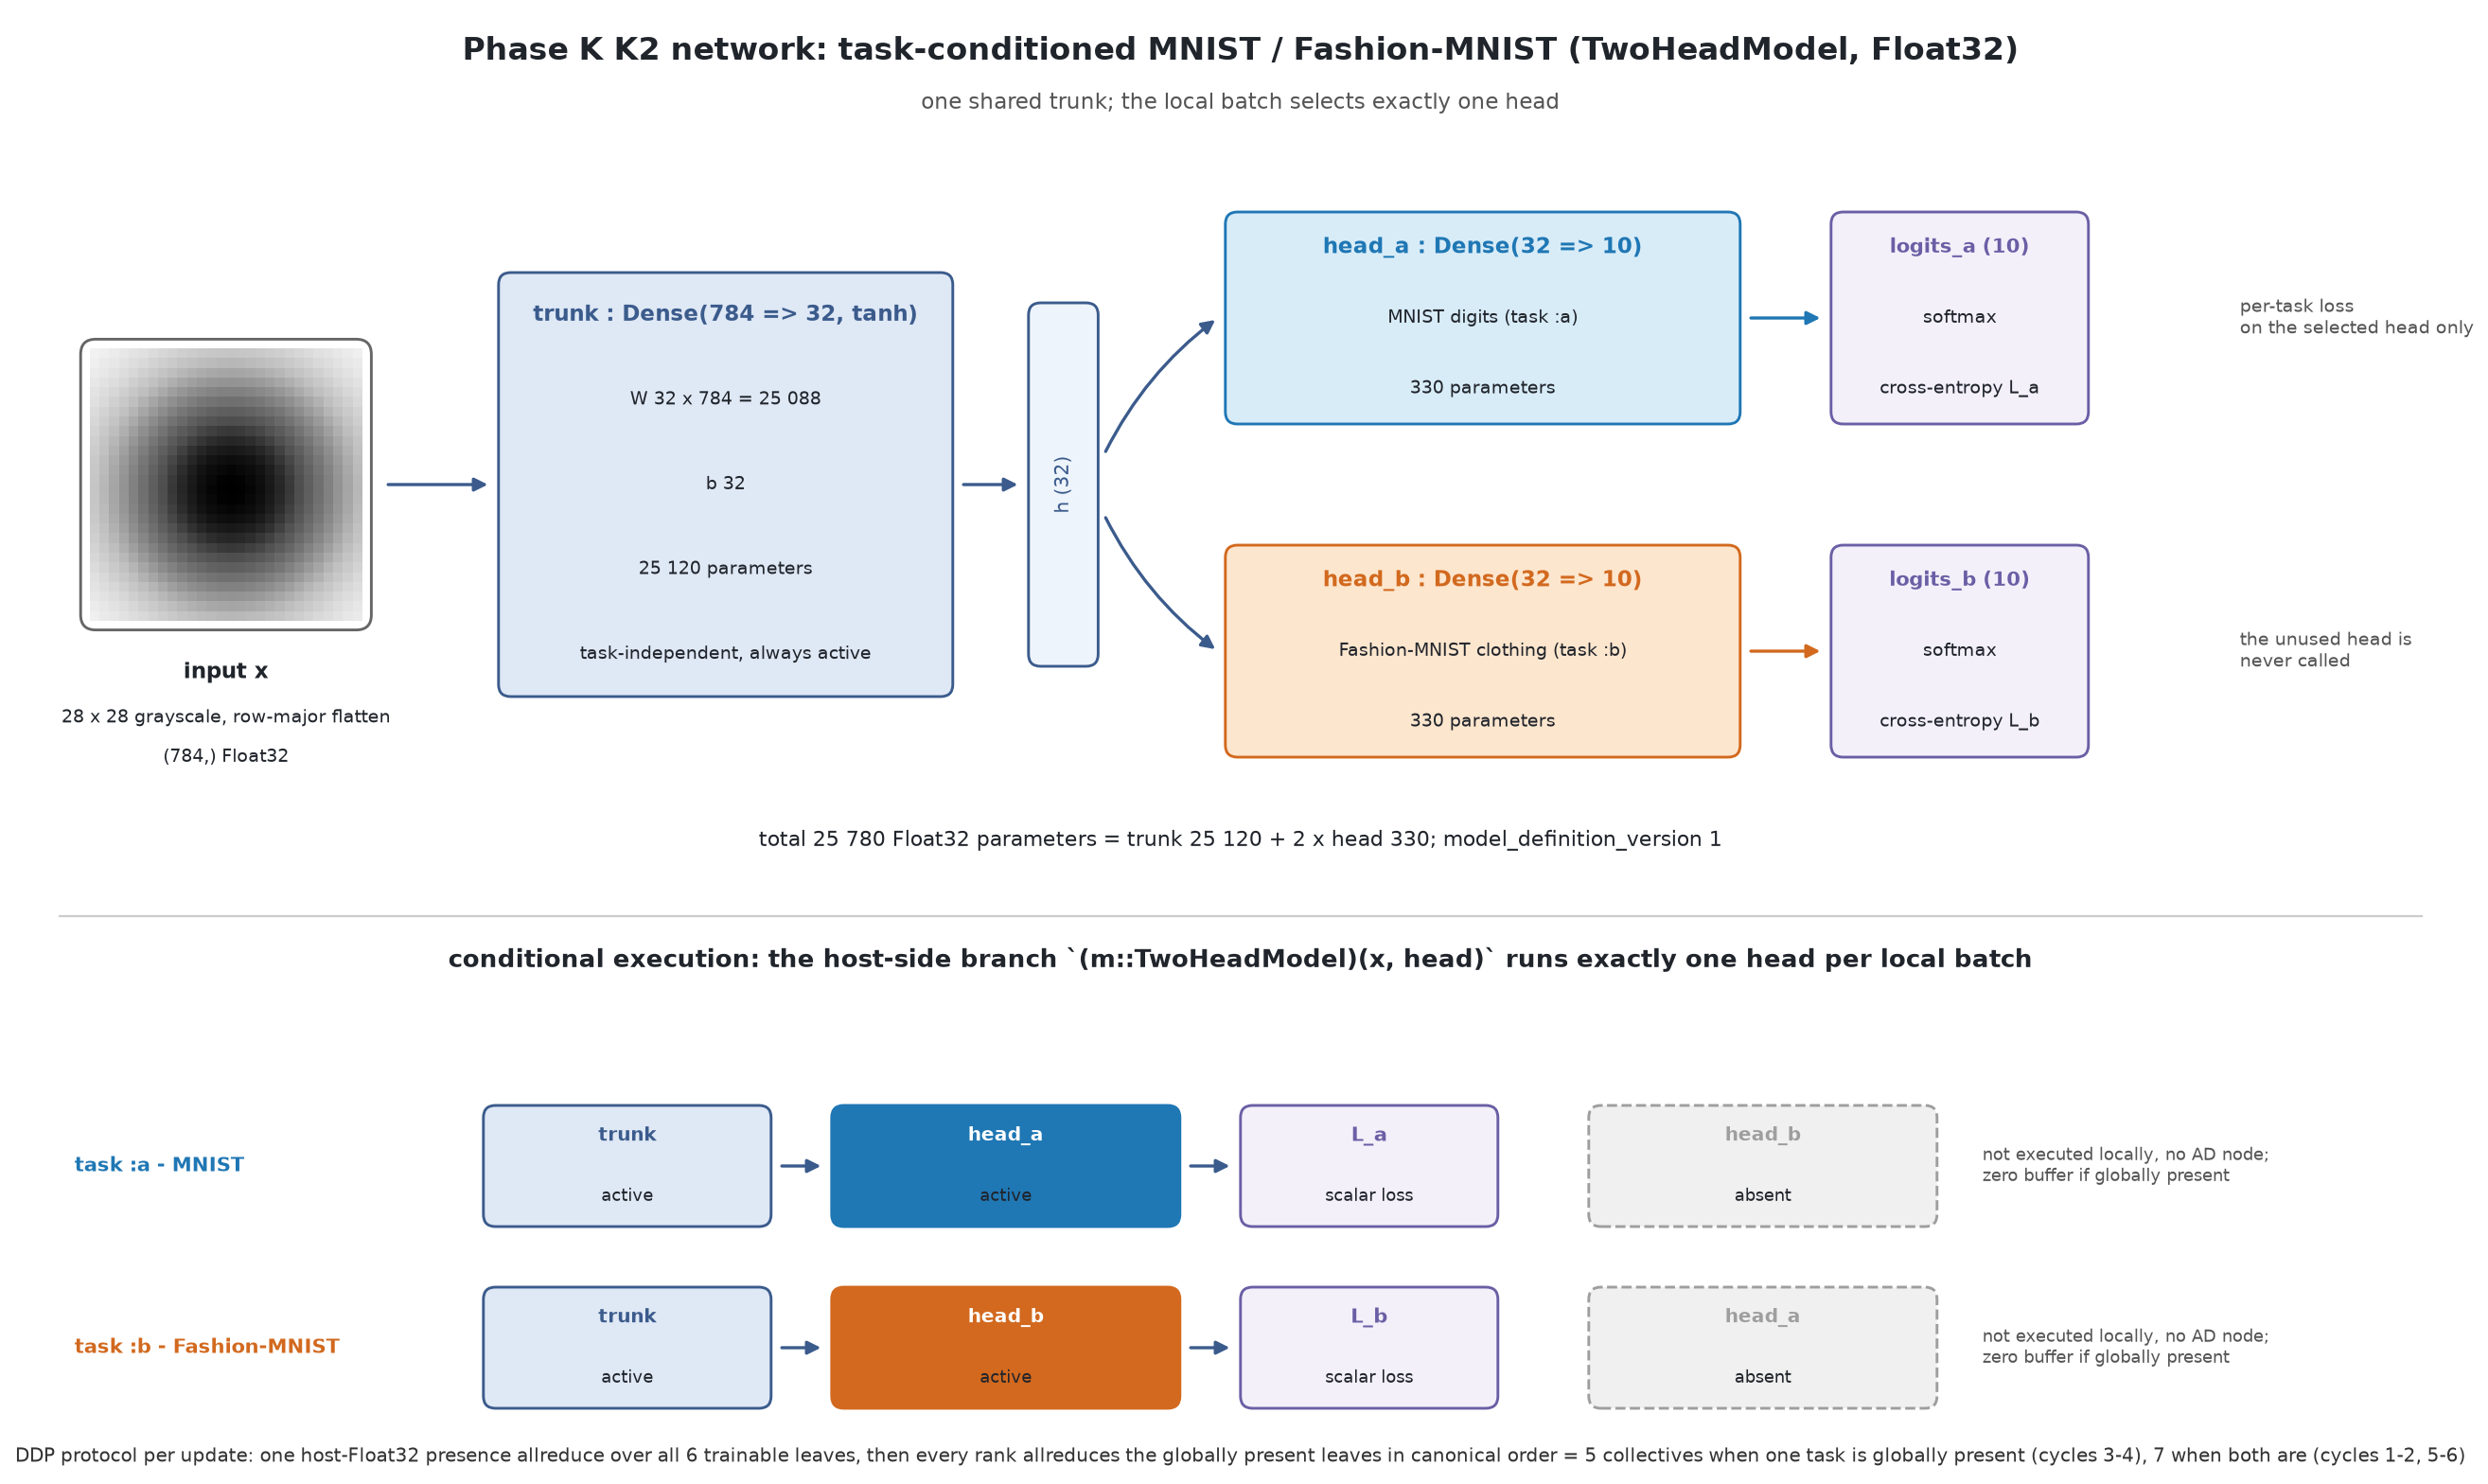

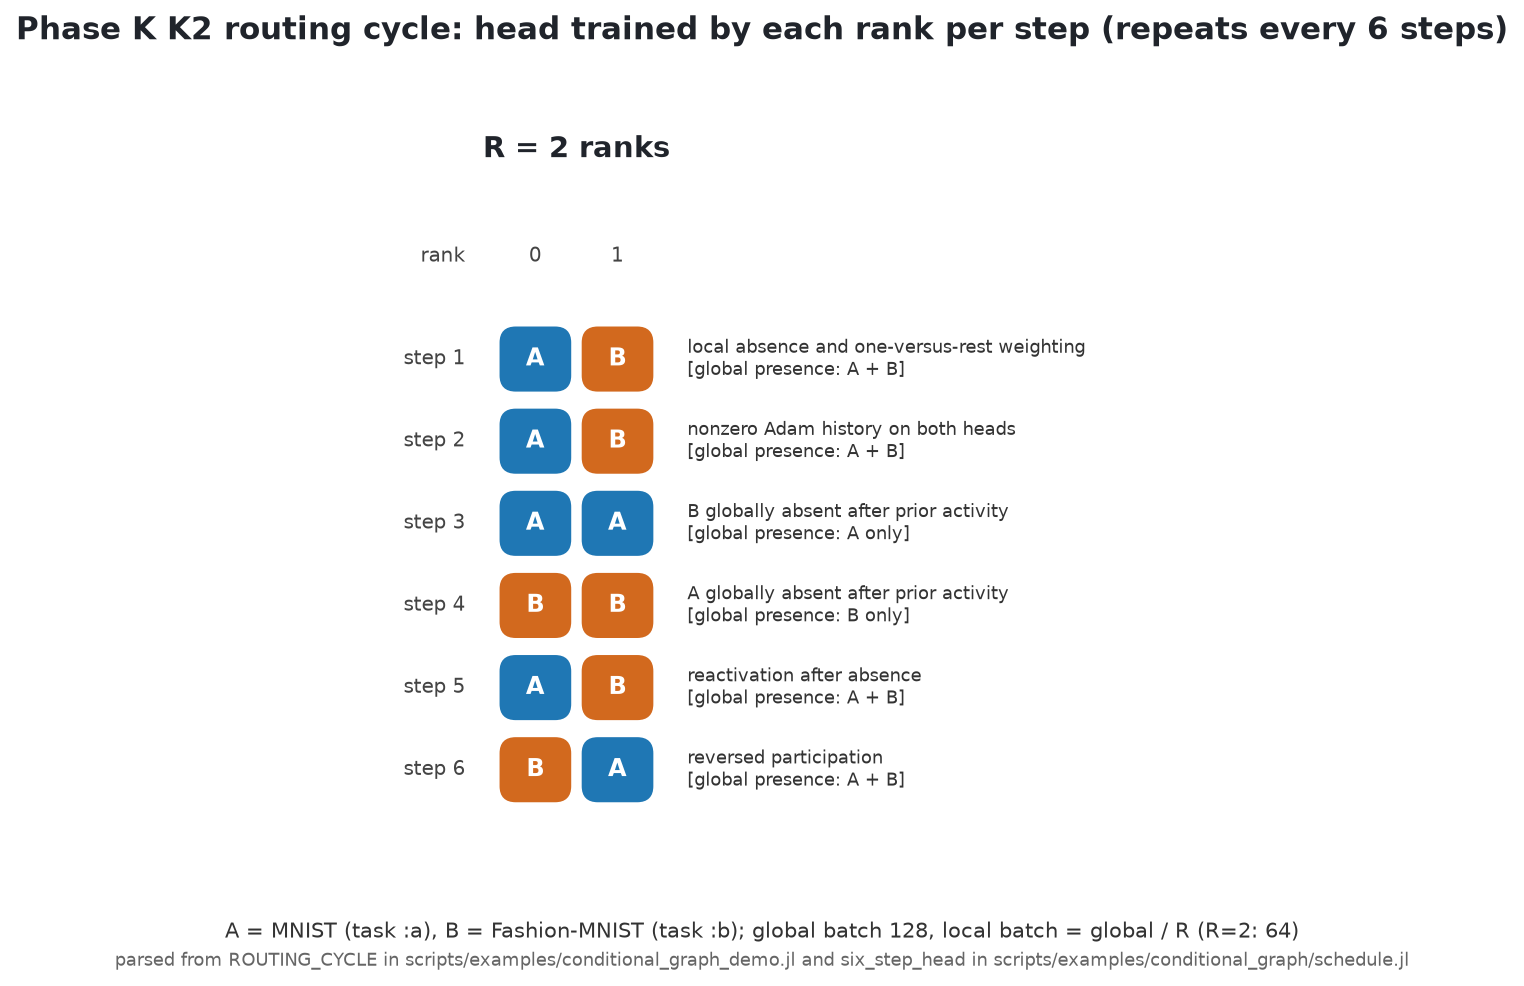

In [6]:
if regenerate_figures
    netfigs = render_network_figures(bundle)
else
    netdir = joinpath(REPO_ROOT, "notebook", "figures",
        "conditional_graph_distributed_workflow", bundle.key, "network")
    netfigs = (network = joinpath(netdir, "phase-k-k2-network.png"),
        routing = joinpath(netdir, "phase-k-k2-routing.png"))
end
display_png(netfigs.network)
display_png(netfigs.routing)

In [7]:
schedule_cross_check(data)

cycle phase,task A ranks,task B ranks,routing rule
1,20,20,"rank 0 task A, others task B"
2,20,20,"rank 0 task A, others task B"
3,40,0,all task A
4,0,40,all task B
5,20,20,"rank 0 task A, others task B"
6,20,20,"rank 0 task B, others task A"


**Observation.** The network diagram reports the exact parameter counts parsed
from the example sources: trunk 25,120 + 330 per head = 25,780. The routing
grid is drawn for the configured rank count, and the saved schedule table
cross-check confirms every `(step, rank)` head assignment against the six-step
rule.

**Interpretation.** The schedule is data, saved before training. Every rank and
the independent single-process reference consume the same identity
`(task, pool_index)` sequence, which is what makes the later per-step
comparisons meaningful.

## 3. Six-step schedule and gradient weighting

The wrapper reduces the per-rank gradients that are present in the local AD
graph and skips parameters that are absent everywhere:

```
g = (1 / R) * sum(g_r for r in 0:R-1)
```

Each local loss is a batch mean, and all ranks use equal local batch sizes, so
the reduction is the global sample mean. The denominator is the **total rank
count** `R`, not the number of active ranks. A parameter that is locally absent
contributes zero from that rank. A parameter that is globally absent keeps its
value and its Adam history: the update is skipped. Four-rank mixed steps weight
the two tasks 1/4 and 3/4; two-rank mixed steps weight them 1/2 and 1/2.

**Question.** What weights did each rank take per step, and how much data did
each task consume?

figures written under: /home/kurapica/Projects/ddp_flux/ddp-flux-thesis/notebook/figures/conditional_graph_distributed_workflow/tutorial-2rank


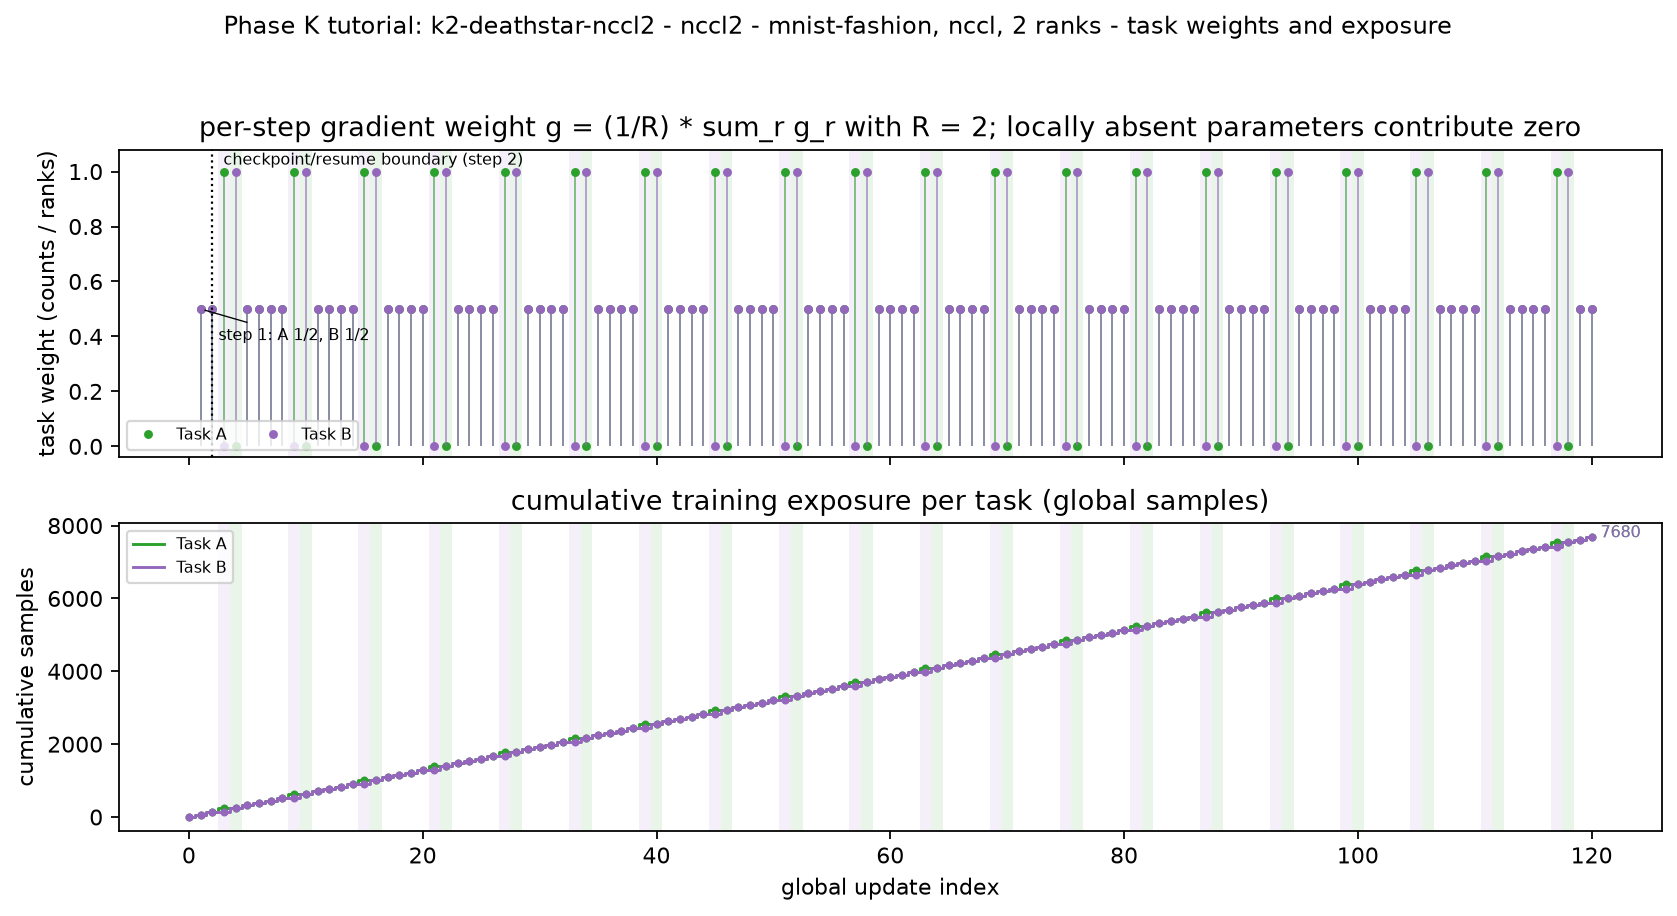

In [8]:
if regenerate_figures
    figs = render_demo_figures(bundle)
else
    figs = demo_figures(joinpath(REPO_ROOT, "notebook", "figures",
        "conditional_graph_distributed_workflow", bundle.key))
end
println("figures written under: ", figs.directory)
display_png(figs.exposure)

In [9]:
exposure = exposure_summary(data)
display(md_table(["task", "final exposure", "mixed-step weights", "note"], exposure.rows))
for row in exposure.rows
    println("Task ", row[1], ": final exposure ", row[2],
        " samples; mixed-step weights ", row[3], ".")
end
println("Total scheduled samples: ", exposure.total,
    " (global batch 128 x 120 steps).")

task,final exposure,mixed-step weights,note
A,7680,"1/2, 1/2",samples = 7680 (global batch 128 x 120 steps = 15360)
B,7680,"1/2, 1/2",samples = 7680 (global batch 128 x 120 steps = 15360)


Task A: final exposure 7680 samples; mixed-step weights 1/2, 1/2.
Task B: final exposure 7680 samples; mixed-step weights 1/2, 1/2.
Total scheduled samples: 15360 (global batch 128 x 120 steps).


**Observation (data-derived).** The printed exposures and mixed-step weights
come from the saved schedule and are cross-checked against the validation
tables and the prepared sample identities. The two tasks share the full global
batch, and the weights are the contributing-rank counts divided by the rank
count.

**Interpretation.** Task exposure differs between rank counts by design of the
routing cycle: the rank count changes the split, not the code. These bundles
also used different hardware, so they do **not** form a scaling experiment.

## 4. Backend initialization, device placement, and optimizer setup

The driver initializes the backend explicitly; there is no automatic CPU
fallback. NCCL requires a functional CUDA stack and enables scalar-indexing
checks (`CUDA.allowscalar(false)`) before any model work. Every rank must land
on a distinct physical device. The optimizer is native Optimisers.jl `Adam`.

The public wrapper path is:

```julia
using Flux, Optimisers
import Flux: DistributedUtils as DU

DU.initialize(DU.NCCLBackend)                        # or DU.MPIBackend
backend = DU.get_distributed_backend(DU.NCCLBackend)
model   = TwoHeadModel(...)                          # shared trunk, two heads
opt     = DU.DistributedOptimizer(backend, Optimisers.Adam(1.0e-3))
state   = Optimisers.setup(opt, model)               # -> DistributedOptimizerState
# local AD outside the wrapper, then one distributed update:
state, model = Optimisers.update!(state, model, gs)  # returns new state and model
```

The returned `state` is a `DistributedOptimizerState`; its inner Optimisers
tree is `state.tree`. `Optimisers.update!` returns the updated values, which
the fixed-step loop keeps. Communication stays outside automatic
differentiation. The wrapper must be the outermost rule; composing it inside
`OptimiserChain` or `DistributedOptimizer` is rejected.

The campaign's native-tree reconstruction (`state = DistributedOptimizerState(backend, tree)` after loading a data-only checkpoint) is described in
section 8. The public `Optimisers.setup` path above is the normal setup path.

**Question.** Does the current `flux-integration` worktree still contain the
public API and the training-loop sequence the tutorial describes?

In [10]:
api_path = joinpath(FLUX_WORKTREE, "src", "distributed", "public_api.jl")
api_source = read(api_path, String)
required_api = [
    "struct DistributedOptimizer",
    "function Optimisers.setup(opt::DistributedOptimizer, model)",
    "struct DistributedOptimizerState",
    "@functor DistributedOptimizerState (tree,)",
    "function Optimisers.update!(s::DistributedOptimizerState, model, grads, higher...)",
]
for needle in required_api
    occursin(needle, api_source) || error("public API source is missing: " * needle)
end

driver_path = joinpath(REPO_ROOT, "scripts", "examples", "conditional_graph_demo.jl")
driver_source = read(driver_path, String)
required_driver = [
    "DU.initialize(DU.NCCLBackend)",
    "CUDA.allowscalar(false)",
    "Zygote.withgradient",
    "state, model = Optimisers.update!(state, model, gs)",
]
for needle in required_driver
    occursin(needle, driver_source) || error("driver source is missing: " * needle)
end

function print_snippet(path, needle; after = 4)
    lines = readlines(path)
    index = findfirst(line -> occursin(needle, line), lines)
    index === nothing && error("snippet not found: " * needle)
    for i in index:min(length(lines), index + after)
        println(lpad(i, 4), ": ", lines[i])
    end
end
println("resolved implementation: ", api_path)
println()
print_snippet(api_path, "function Optimisers.setup(opt::DistributedOptimizer, model)")
println()
print_snippet(driver_path, "state, model = Optimisers.update!(state, model, gs)"; after = 6)

resolved implementation: /home/kurapica/Projects/ddp_flux/flux-integration/src/distributed/public_api.jl



 440: function Optimisers.setup(opt::DistributedOptimizer, model)
 441:     opt.opt isa DistributedOptimizer && throw(ArgumentError(_COMPOSE_ERROR))
 442:     return DistributedOptimizerState(opt.backend, Optimisers.setup(opt.opt, model))
 443: end
 444: 

 452:         state, model = Optimisers.update!(state, model, gs)
 453:         CGCommon.ensure(Functors.fmap(host_copy, gs) == caller_grads, "caller gradients mutated at step $step")
 454:         check_structure(model, state.tree)
 455:         CGCommon.check_leaf_config(config_initial, state.tree; context="post-update step $step rank $rank")
 456:         if rank == 0
 457:             CGCommon.check_leaf_config(config_initial, ref_tree; context="post-update reference step $step")
 458:         end


**Observation.** The public API anchor points and the fixed-step update
sequence exist verbatim in the current worktree, at the reported line numbers.

**Interpretation.** The examples in this notebook describe the implementation
that produced the artifacts, not an older or hypothetical API. `update!` is
in-place for the state and returns the (possibly re-created) model values; the
driver keeps both.

## 5. Local AD, then the distributed update outside AD

Every step follows the same order on every rank:

1. Read the scheduled local batch and its selected head.
2. Differentiate the local batch mean once with Zygote, outside every
   distributed call: the unused head is absent from the local AD graph.
3. Hand the gradients to `Optimisers.update!` on the `DistributedOptimizerState`.
   The wrapper fills missing gradients with zero, runs one in-place presence
   reduction followed by one gradient reduction per present leaf, and then
   delegates to native Adam.
4. The independent single-process reference computes the same global objective
   from the saved schedule and updates its own native tree.
5. Compare parameters, both Adam moments, and the decay products against the
   reference; the absent head must be untouched on skip steps.

Every collective is taken by every rank in the same order. The denominator in
the gradient reduction is the total rank count, which is why equal
participation (equal local batch sizes and update counts) is a requirement.

**Question.** Do the collective traces show the documented ordering: one CPU
presence reduction, then ordered gradient reductions?

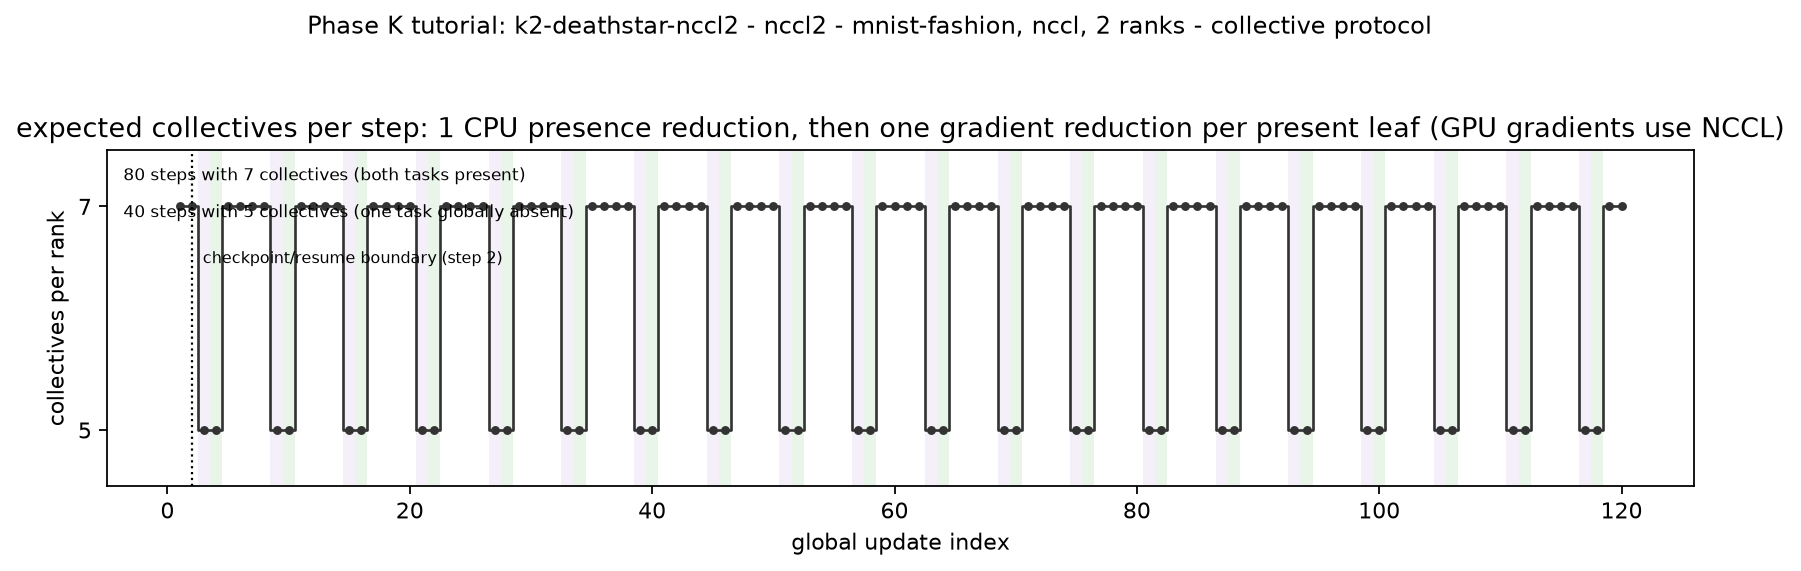

mode,collectives per rank,rank-step records,meaning
train,5,80,one task globally absent
train,7,160,both tasks present
resume,5,80,one task globally absent
resume,7,156,both tasks present


verified: presence reduction is one CPU Vector{Float32} average, first in every step
verified: order 1 precedes every gradient reduction (orders 2..n are contiguous)
verified: observed collectives per rank equal the 5/7 protocol on every step
verified: global presence flags equal the rank mean of the local flags
verified: every gradient reduction uses a CUDA buffer (NCCL transport)


In [11]:
display_png(figs.collectives)
checks = collective_summary(data)
display(md_table(["mode", "collectives per rank", "rank-step records", "meaning"], checks.rows))
for check in checks.checks
    println("verified: ", check)
end

In [12]:
traces = representative_traces(data; steps = (1, 3), rank = 0)
println("ordered trace, step 1 rank 0 (mixed split, 7 collectives):")
display(traces[1])
println("ordered trace, step 3 rank 0 (all task A, 5 collectives):")
display(traces[3])

ordered trace, step 1 rank 0 (mixed split, 7 collectives):


order,type,shape,op,local flags,global flags
1,Vector{Float32},"(6,)",avg,"Float32[1.0, 1.0, 1.0, 1.0, 0.0, 0.0]","Float32[1.0, 1.0, 0.5, 0.5, 0.5, 0.5]"
2,"CUDACore.CuArray{Float32, 2, CUDACore.DeviceMemory}","(32, 784)",avg,–,–
3,"CUDACore.CuArray{Float32, 1, CUDACore.DeviceMemory}","(32,)",avg,–,–
4,"CUDACore.CuArray{Float32, 2, CUDACore.DeviceMemory}","(10, 32)",avg,–,–
5,"CUDACore.CuArray{Float32, 1, CUDACore.DeviceMemory}","(10,)",avg,–,–
6,"CUDACore.CuArray{Float32, 2, CUDACore.DeviceMemory}","(10, 32)",avg,–,–
7,"CUDACore.CuArray{Float32, 1, CUDACore.DeviceMemory}","(10,)",avg,–,–


ordered trace, step 3 rank 0 (all task A, 5 collectives):


order,type,shape,op,local flags,global flags
1,Vector{Float32},"(6,)",avg,"Float32[1.0, 1.0, 1.0, 1.0, 0.0, 0.0]","Float32[1.0, 1.0, 1.0, 1.0, 0.0, 0.0]"
2,"CUDACore.CuArray{Float32, 2, CUDACore.DeviceMemory}","(32, 784)",avg,–,–
3,"CUDACore.CuArray{Float32, 1, CUDACore.DeviceMemory}","(32,)",avg,–,–
4,"CUDACore.CuArray{Float32, 2, CUDACore.DeviceMemory}","(10, 32)",avg,–,–
5,"CUDACore.CuArray{Float32, 1, CUDACore.DeviceMemory}","(10,)",avg,–,–


**Observation (data-derived).** The measured trace always starts with one
`Vector{Float32}` presence average of six flags; the global flags equal the
rank mean of the local flags. Then come 7 (both tasks present) or 5 (one task
globally absent) gradient reductions. On these NCCL runs every gradient buffer
is a `CuArray`, so the transport is NCCL. The verified counts above cover every
train and resume rank-step record at the selected rank count.

**Interpretation.** The collective count is a function of global presence, not
of the local branch. On a step where a head is globally absent, its four
gradient collectives do not appear and its optimizer step is skipped while the
Adam history is preserved. Loss reduction alone would not establish this; the
counts and the ordered traces do.

## 6. Reference comparisons: parameters, Adam state, and validation

The independent reference differentiates the scheduled global objective once,
in one process, with plain Zygote and Optimisers. There is one reference
element per **global update**, not per rank. Replica and reference errors are
reported separately, and scalar agreement counts (`peer_beta_exact`) are kept
alongside them.

**Question.** How close are the DDP replicas to the independent native
reference across the whole run?

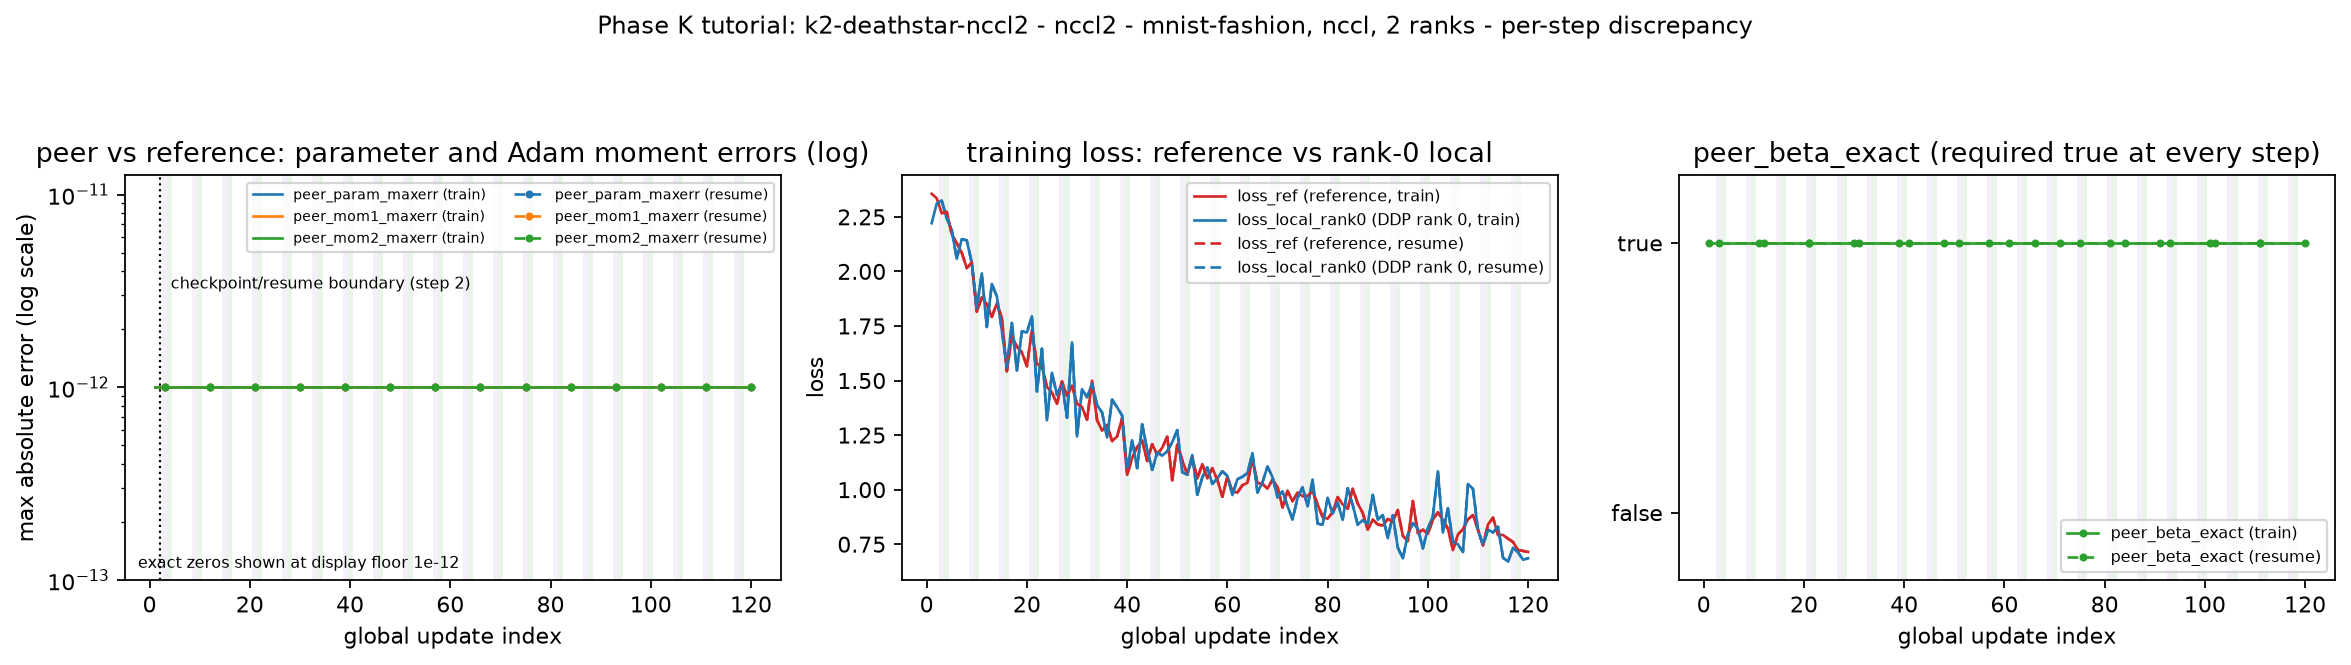

quantity,maximum over train + resume,acceptance
peerparammaxerr,0.000e+00,"within atol=2.0e-6, rtol=1.0e-5"
peermom1maxerr,0.000e+00,within tolerance
peermom2maxerr,0.000e+00,within tolerance
peerbetaexact false records,0,every decay product matched


recorded campaign status: PASS


In [13]:
display_png(figs.discrepancy)
d = discrepancy_summary(data)
display(md_table(["quantity", "maximum over train + resume", "acceptance"],
    [["peer_param_maxerr", @sprintf("%.3e", d.maxima.param),
      "within atol=2.0e-6, rtol=1.0e-5"],
     ["peer_mom1_maxerr", @sprintf("%.3e", d.maxima.mom1), "within tolerance"],
     ["peer_mom2_maxerr", @sprintf("%.3e", d.maxima.mom2), "within tolerance"],
     ["peer_beta_exact false records", string(d.n_false),
      d.n_false == 0 ? "every decay product matched" : "MISMATCH"]]))
println("recorded campaign status: ", summary_status(data.paths.summary))

**Observation (data-derived).** The table above reports the raw maxima
separately from the acceptance statement, and `peer_beta_exact` is true at
every recorded step, so the Adam decay products agree exactly. Where a
discrepancy is zero it is an exact zero, not a floored display value.

**Interpretation.** Any tiny nonzero maxima are Float32 accumulation effects
inside the declared `atol`/`rtol`; raw errors and the acceptance result are
never conflated. A bundle whose maxima are exactly zero shows that the
comparison is sensitive enough to distinguish exact agreement from
round-off.

**Question.** What did validation loss and accuracy do for DDP and the
reference, per task?

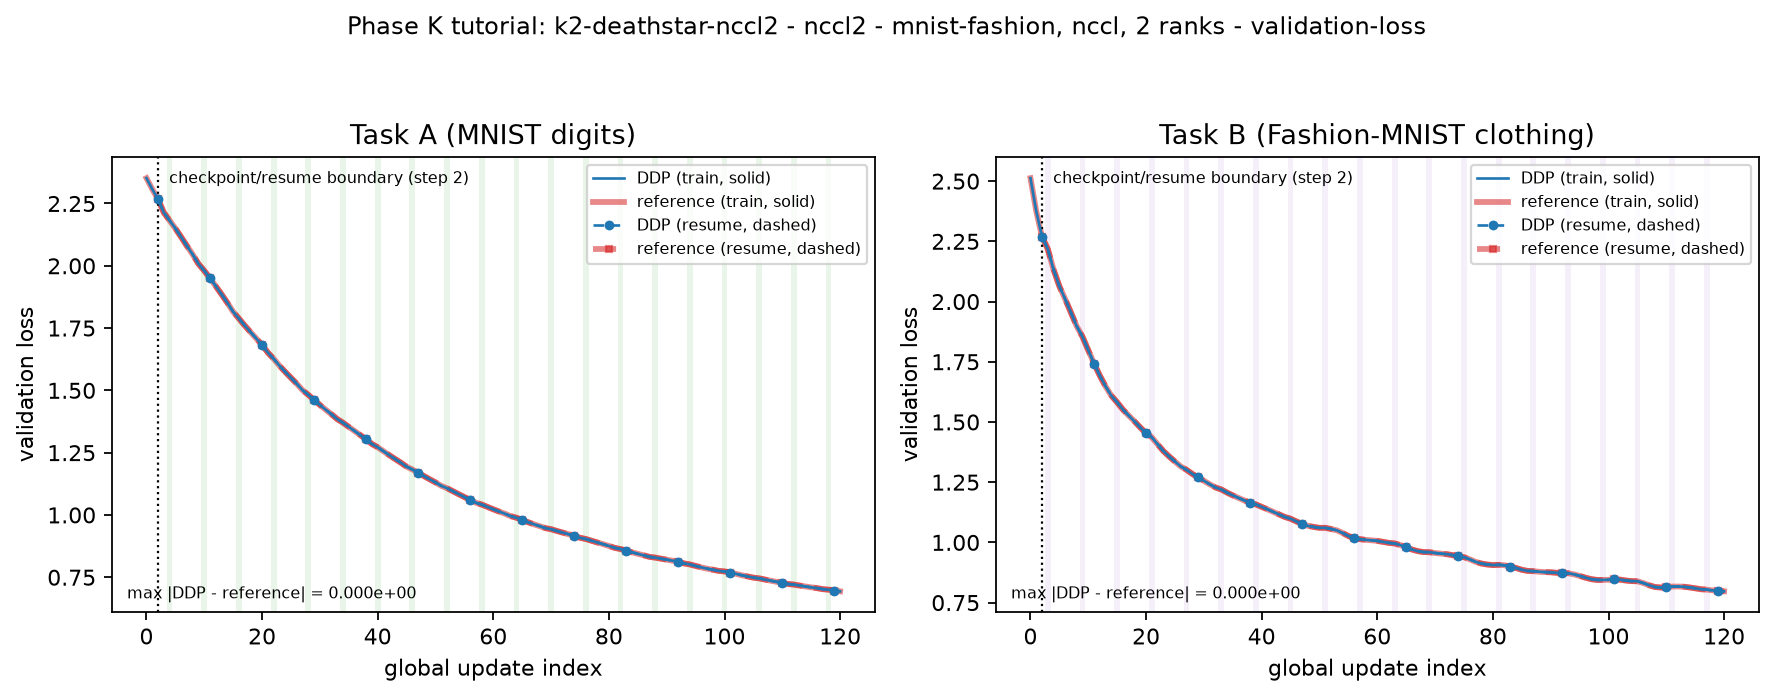

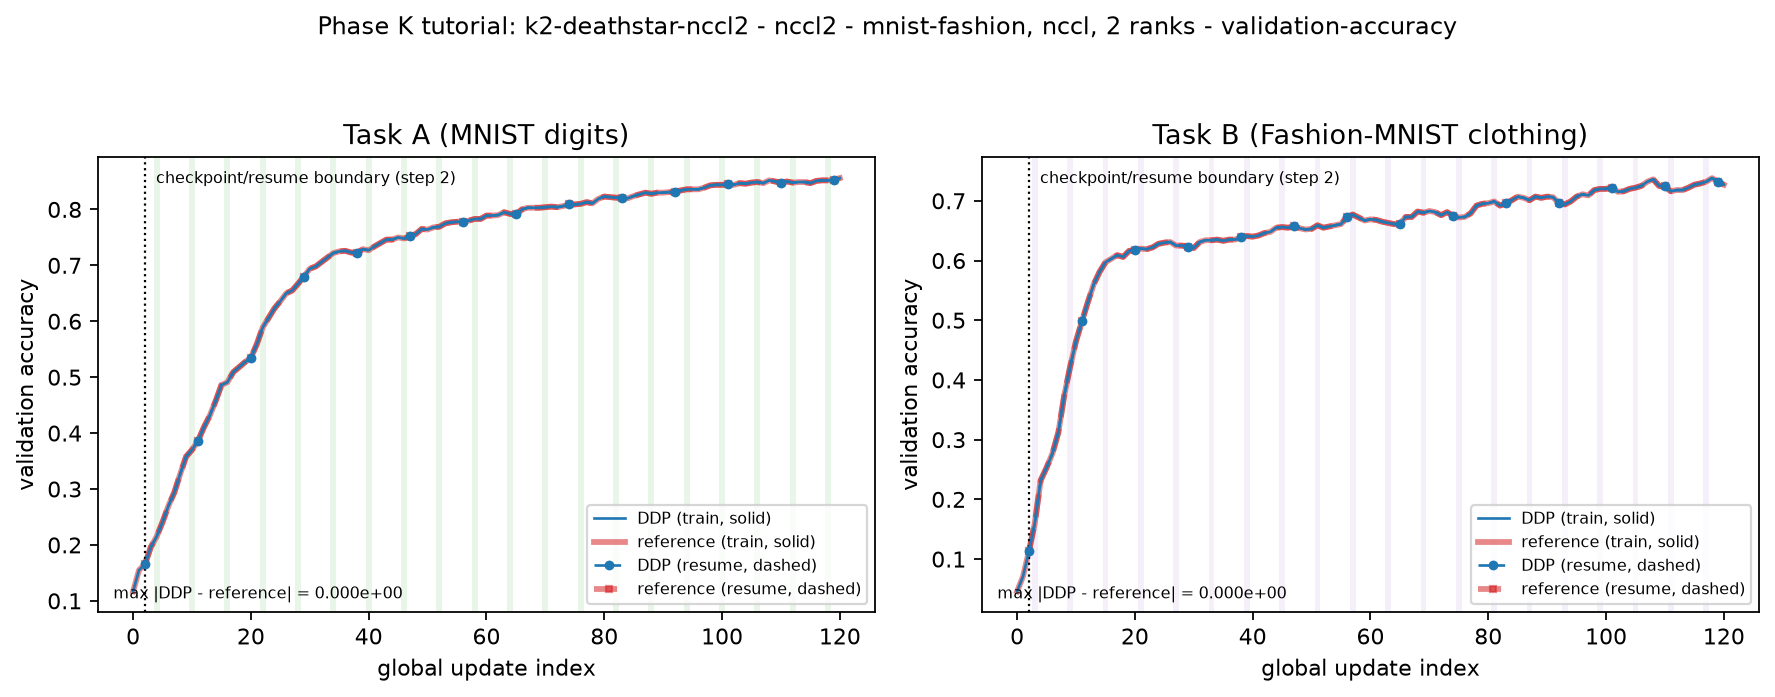

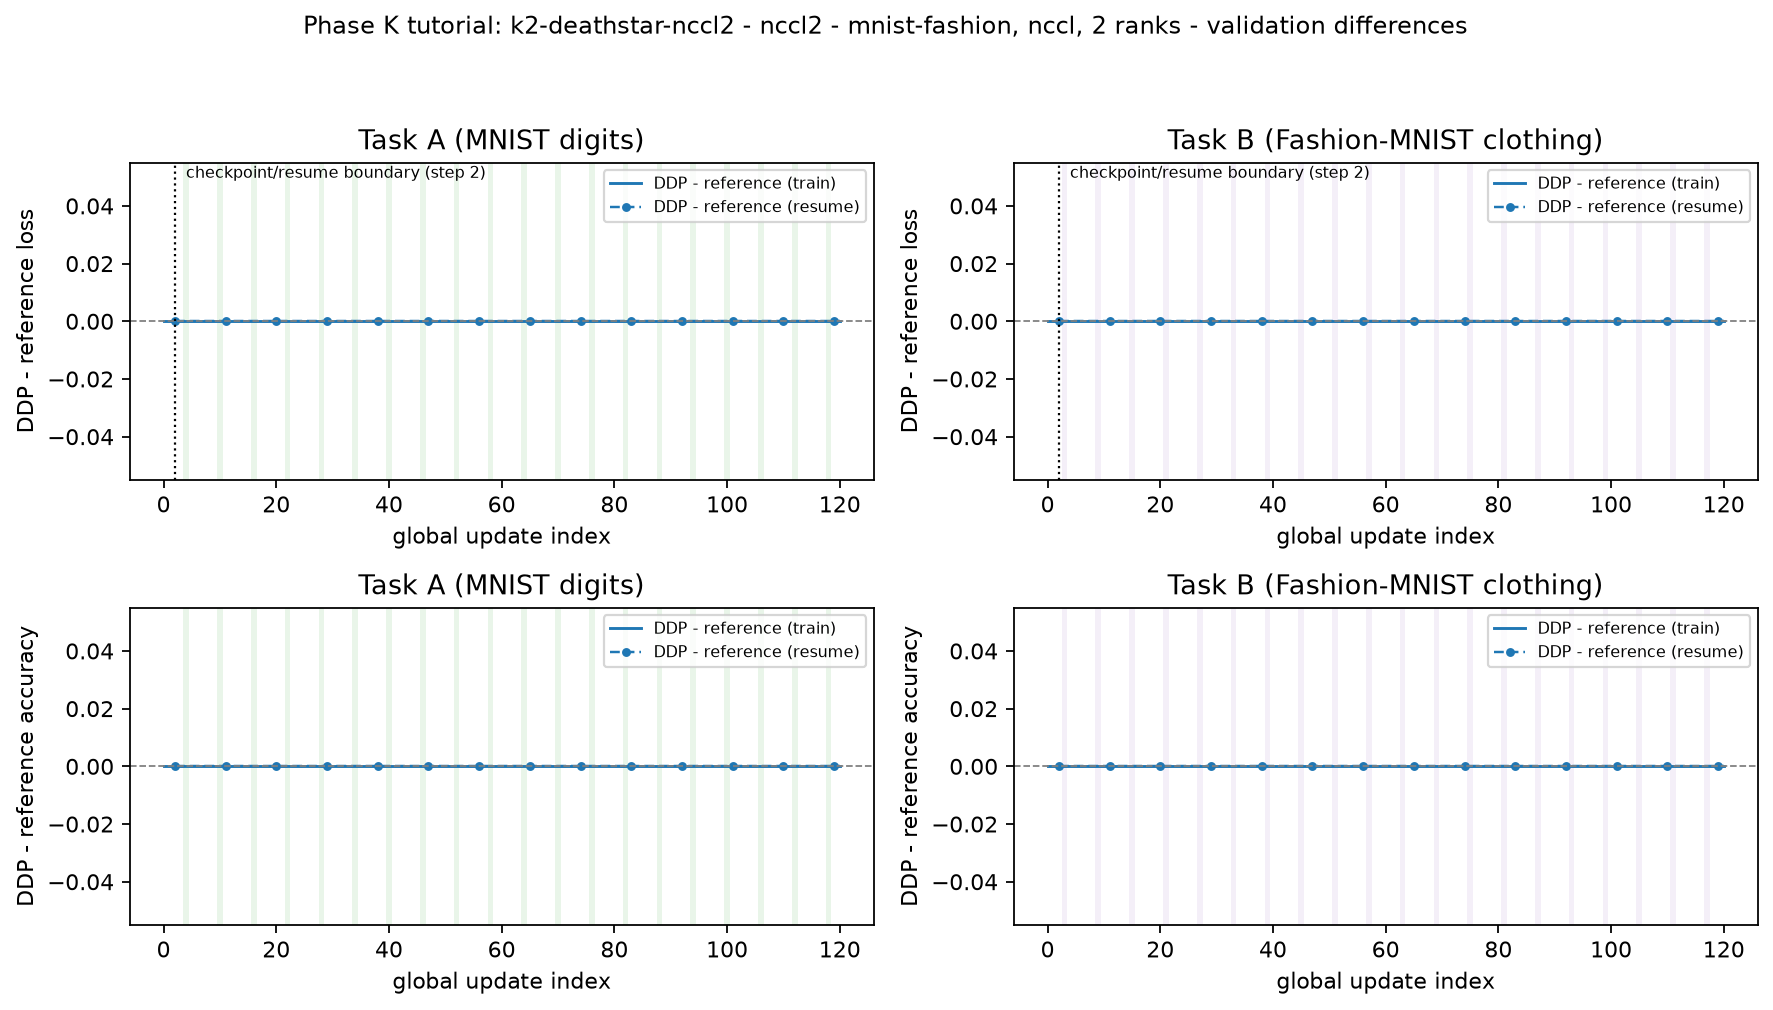

In [14]:
display_png(figs.validation_loss)
display_png(figs.validation_accuracy)
display_png(figs.validation_difference)

In [15]:
vs = validation_summary(data)
display(vs.table)
refdiff = max_reference_difference(data)
rows = [[uppercase(task), mode, r.n, @sprintf("%.3e", r.max_loss), @sprintf("%.3e", r.max_acc)]
        for ((task, mode), r) in sort(collect(refdiff))]
display(md_table(["task", "mode", "compared steps", "max |loss diff|", "max |acc diff|"], rows))
for row in vs.rows
    row[2] == "ddp" || continue
    println("mode ", row[1], ", task ", row[3], ": final loss ", row[8],
        ", final accuracy ", row[9], ", exposure ", row[10])
end

mode,model,task,first step,first loss,first acc,final step,final loss,final acc,final exposure
train,ddp,A,0,2.3518,0.1170,120,0.6935,0.8560,7680
train,ddp,B,0,2.5125,0.0460,120,0.7968,0.7270,7680
train,reference,A,0,2.3518,0.1170,120,0.6935,0.8560,7680
train,reference,B,0,2.5125,0.0460,120,0.7968,0.7270,7680
resume,ddp,A,2,2.2673,0.1650,120,0.6935,0.8560,7680
resume,ddp,B,2,2.2699,0.1130,120,0.7968,0.7270,7680
resume,reference,A,2,2.2673,0.1650,120,0.6935,0.8560,7680
resume,reference,B,2,2.2699,0.1130,120,0.7968,0.7270,7680


| task | mode | compared steps | max |loss diff| | max |acc diff| |
| --- | --- | --- | --- | --- |
| A | resume | 119 | 0.000e+00 | 0.000e+00 |
| A | train | 121 | 0.000e+00 | 0.000e+00 |
| B | resume | 119 | 0.000e+00 | 0.000e+00 |
| B | train | 121 | 0.000e+00 | 0.000e+00 |

mode train, task A: final loss 0.6935, final accuracy 0.8560, exposure 7680
mode train, task B: final loss 0.7968, final accuracy 0.7270, exposure 7680
mode resume, task A: final loss 0.6935, final accuracy 0.8560, exposure 7680
mode resume, task B: final loss 0.7968, final accuracy 0.7270, exposure 7680


**Observation (data-derived).** Both tasks start at chance-level accuracy and
improve; the DDP and reference overlays are visually coincident. The maximum
recorded DDP-minus-reference differences, per task and mode, are in the tables
above. Accuracy is bounded by 0 and 1, and the difference panel keeps matching
overlays visible.

**Interpretation.** Task-specific results are reported together with exposure.
Loss reduction alone does not establish correctness; the per-step parameter,
moment, and decay-product checks do.

## 7. Configured learning rate and predictions

The configured learning rate is recorded per step, rank, and leaf. It is the
Adam `eta` from the fixed configuration, not an effective step-size estimate.

**Question.** Was the optimizer configuration constant for every rank and the
reference?

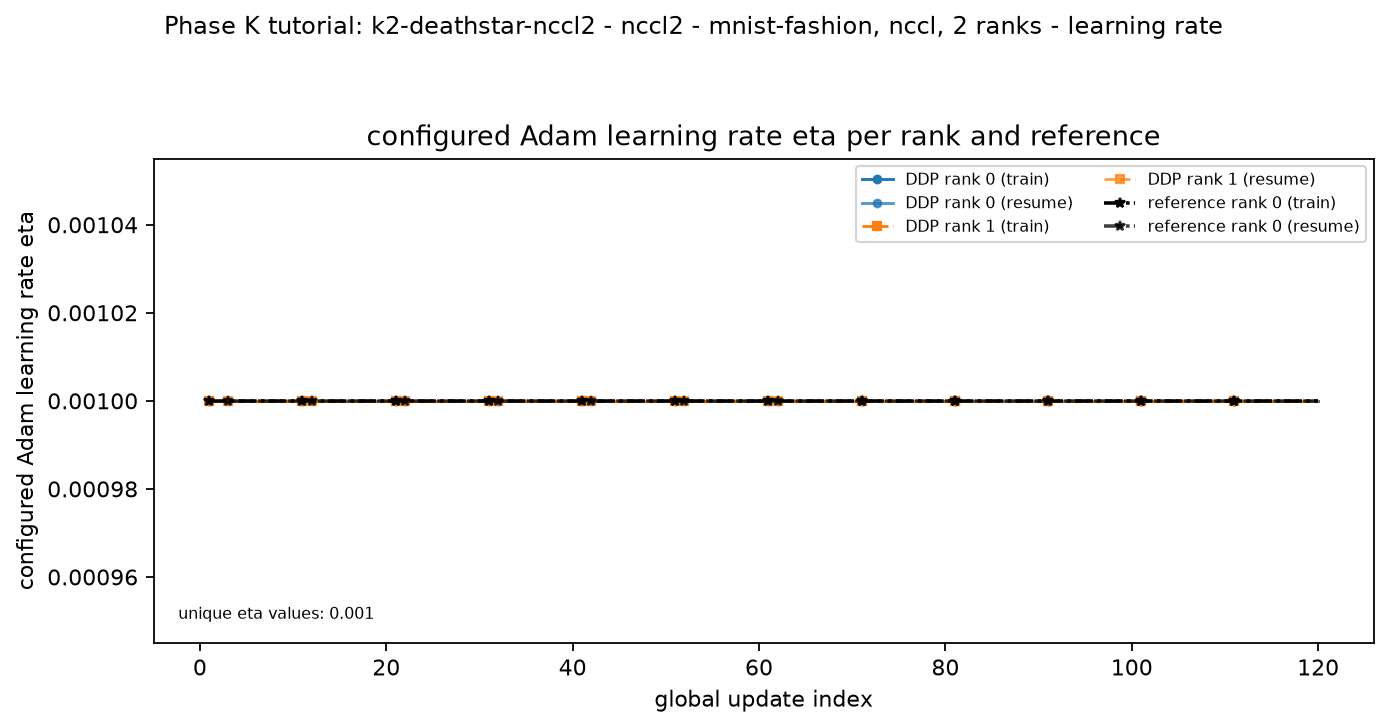

quantity,value
distinct eta values,0.001
canonical leaves,6
DDP ranks,"0, 1"
DDP rate records,2856
reference rate records,1428


In [16]:
display_png(figs.learning_rate)
lr = learning_rate_summary(data)
display(md_table(["quantity", "value"],
    [["distinct eta values", join(lr.etas, ", ")],
     ["canonical leaves", length(lr.leaves)],
     ["DDP ranks", join(lr.ranks, ", ")],
     ["DDP rate records", lr.ddp_records],
     ["reference rate records", lr.reference_records]]))

**Observation (data-derived).** Exactly one `eta` value appears across all six
canonical leaves, every DDP rank, and the reference; the counts are in the
table above and scale with the selected rank count and step horizon.

**Interpretation.** The campaign never changed the learning rate or the
optimizer configuration. Since `eta` is constant and Adam rescales each
coordinate, this plot is a configuration check, not a step-size measurement.

**Question.** Which fixed validation samples were predicted correctly and
which were not?

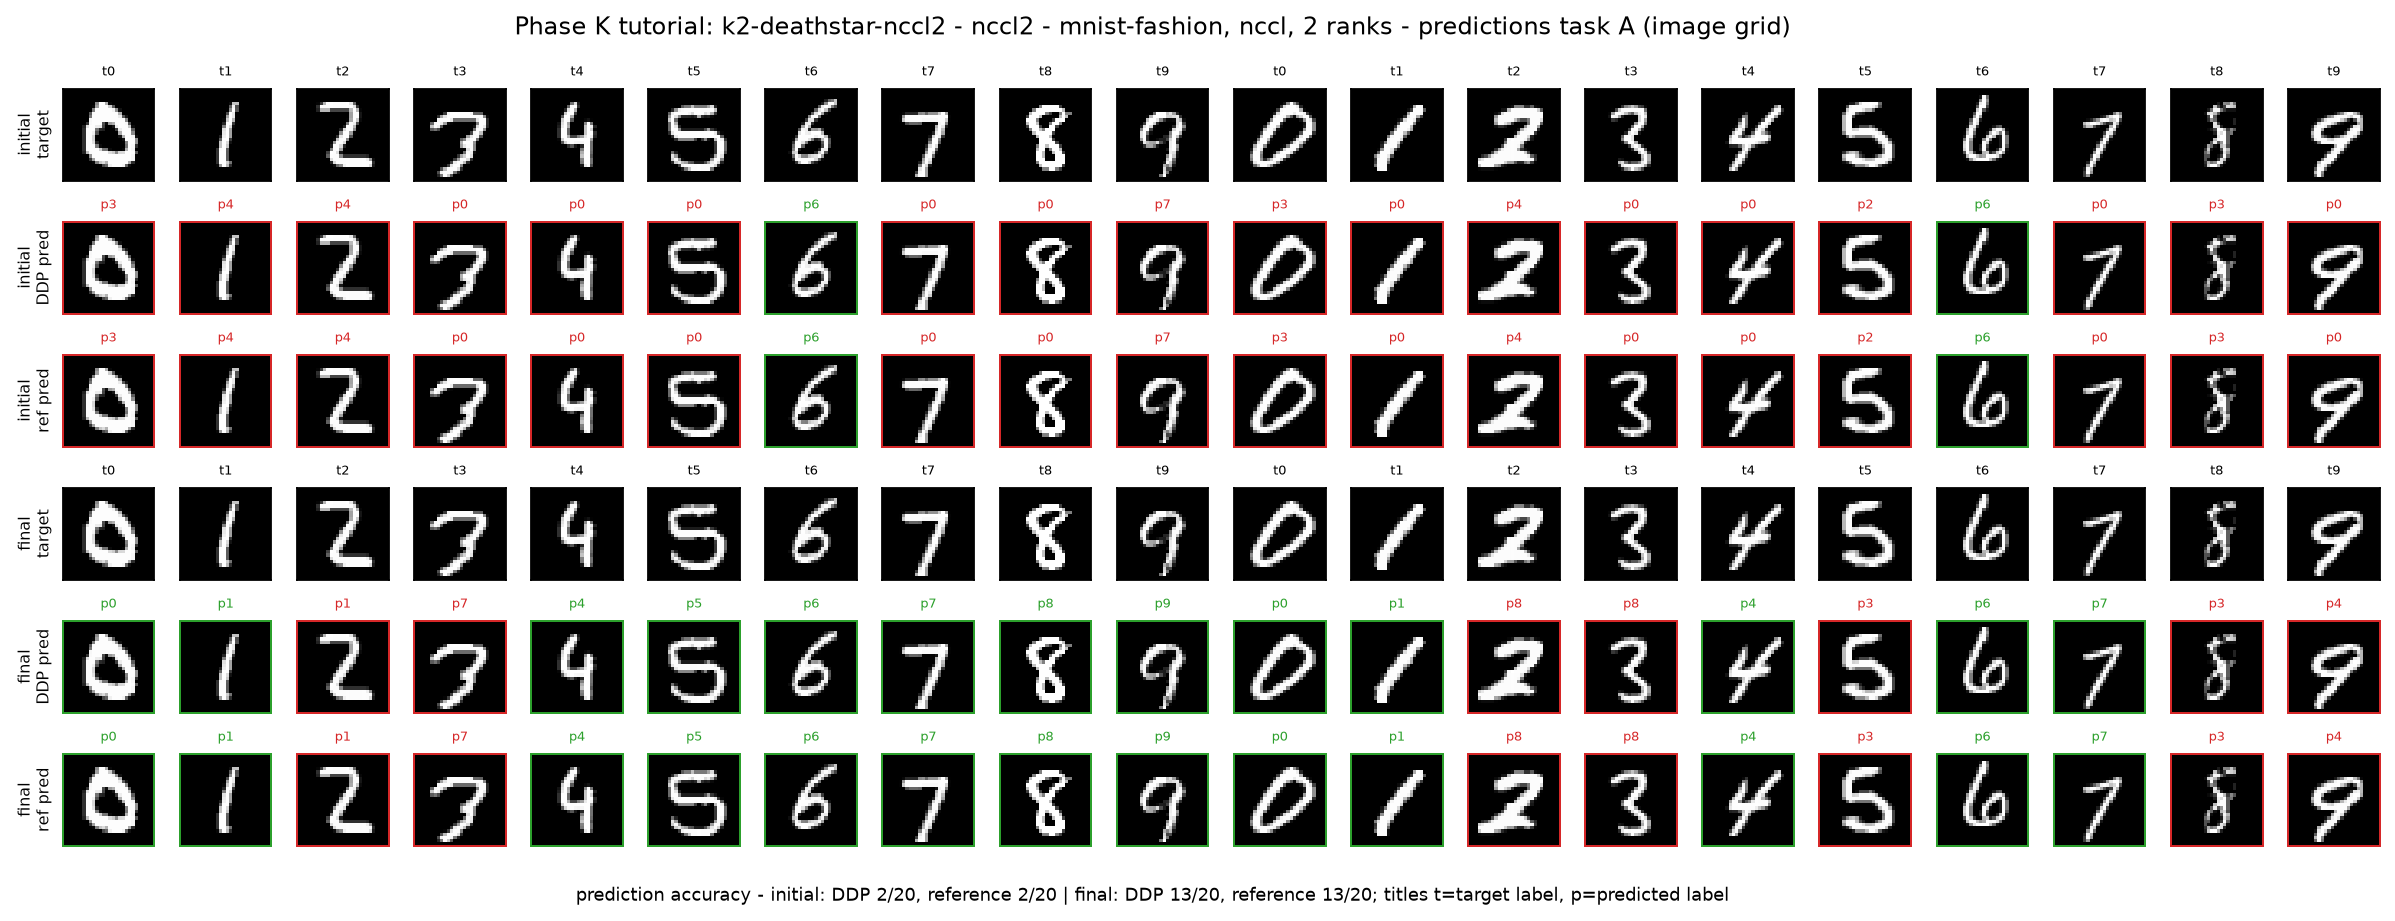

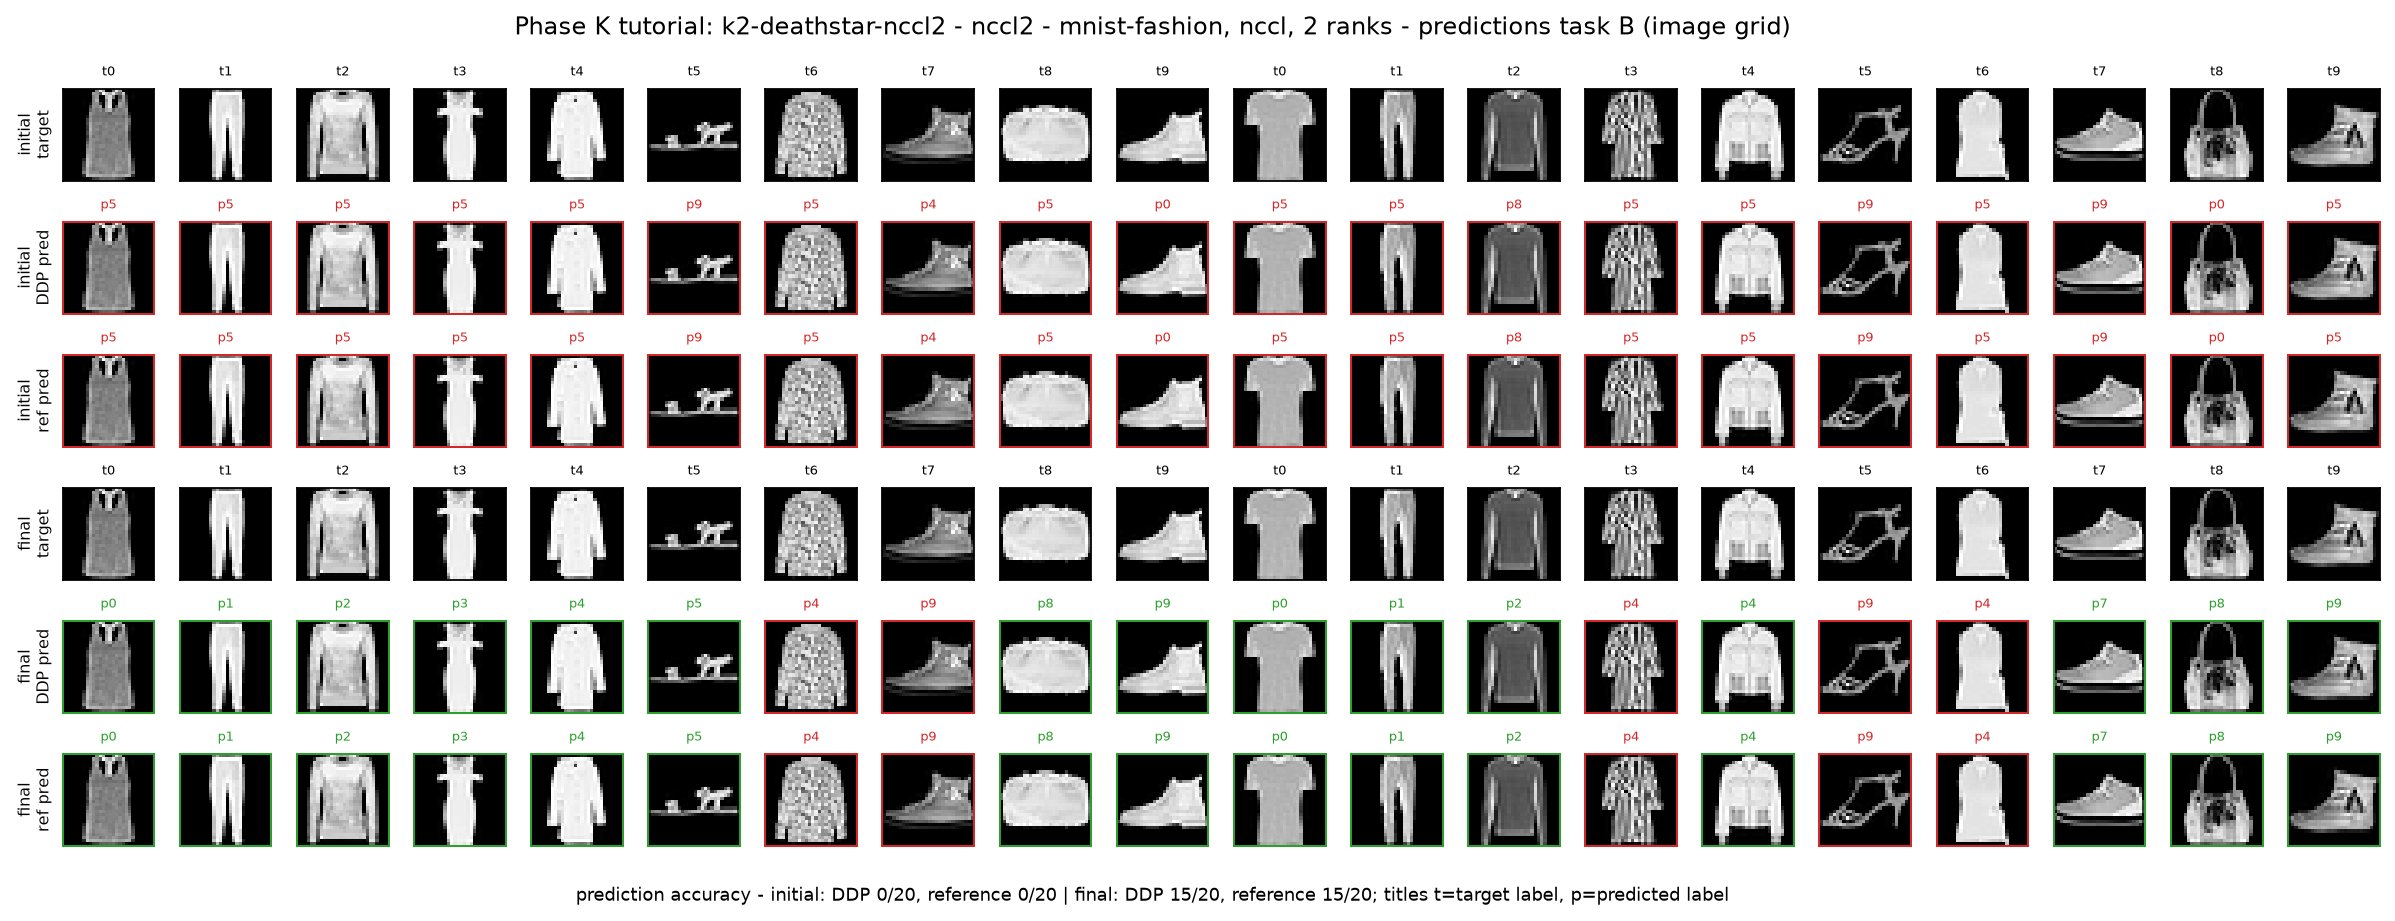

In [17]:
display_png(figs.predictions_a)
display_png(figs.predictions_b)

**Observation.** The prediction figures use the first 20 validation samples of
each task, fixed across the initial and final snapshots; each panel shows the
true class, the predicted class, and the task. Targets and predicted classes
both stay in the ten-class range, and the same sample identity is used by
train and resume.

**Interpretation.** Sample selection is deterministic, and the figures report
errors as well as successes. The prediction snapshot complements the scalar
accuracy with concrete failures; it is not a substitute for the reference
comparison.

## 8. Data-only checkpoint and fresh-process continuation

Training saves a data-only checkpoint after **step 2**: model parameters, the
native Optimisers tree (including both Adam moments), the reference state, the
schedule, and the dataset identity. Fresh processes restore that payload,
reconstruct `DistributedOptimizerState` around the loaded native tree, and
continue at step 3. The backend, rank count, dtype, source hashes, and
tolerances are checked on resume; the wrapper state itself is reconstructed
from the recorded native tree rather than serialized.

Fresh-process resume evidence has two layers:

- `resume_match=true` console markers: every resumed `(step, rank)` record was
  compared with the saved uninterrupted trajectory snapshot.
- Validation metric intersections: the train and resume DDP rows at steps
  3..120 must agree.

**Question.** Does continuation from the data-only checkpoint reproduce the
uninterrupted train trajectory exactly?

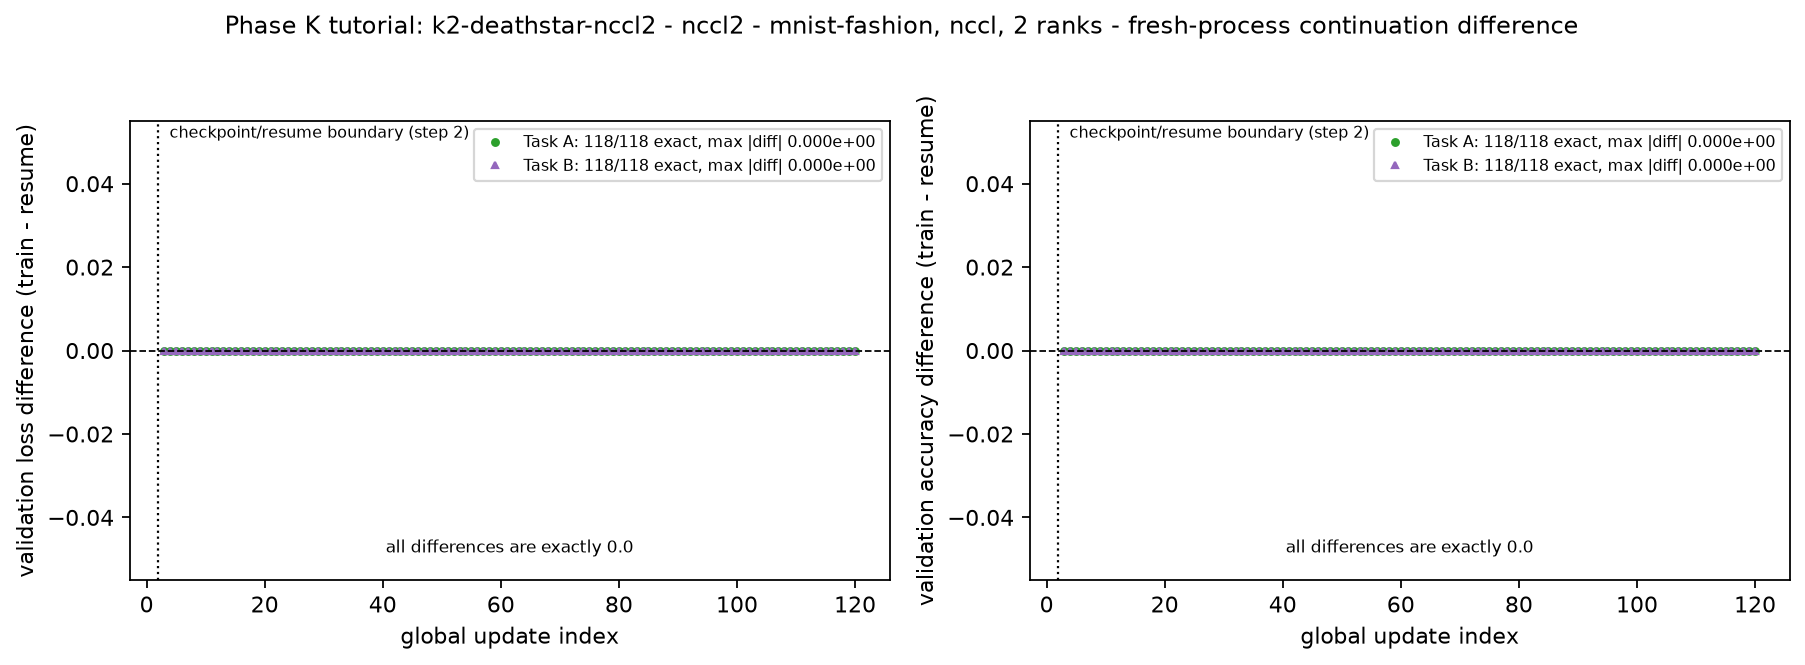

continuation check,matched,total,note
resume markers (console),236,236,all matched
validation task A,118,118,"max |diff| loss 0.000e+00, acc 0.000e+00"
validation task B,118,118,"max |diff| loss 0.000e+00, acc 0.000e+00"



resume markers: 236/236 = ranks x steps after checkpoint = 236
resumed-step parameter/Adam comparisons vs the independent reference:
  peer_param_maxerr = 0.000e+00
  peer_mom1_maxerr  = 

0.000e+00
  peer_mom2_maxerr  = 0.000e+00
  peer_beta_exact true on 236/236 resumed records
per-task metric intersections are exact at every compared step


In [18]:
display_png(figs.continuation)
cont = continuation_summary(data)
display(md_table(["continuation check", "matched", "total", "note"], cont.rows))
println()
println("resume markers: ", cont.n_match, "/", cont.n_total,
    " = ranks x steps after checkpoint = ", cont.expected)
resume_steps = mode_rows(data, "resume")
println("resumed-step parameter/Adam comparisons vs the independent reference:")
println("  peer_param_maxerr = ",
    @sprintf("%.3e", maximum(record.peer_param_maxerr for record in resume_steps)))
println("  peer_mom1_maxerr  = ",
    @sprintf("%.3e", maximum(record.peer_mom1_maxerr for record in resume_steps)))
println("  peer_mom2_maxerr  = ",
    @sprintf("%.3e", maximum(record.peer_mom2_maxerr for record in resume_steps)))
println("  peer_beta_exact true on ",
    count(record -> record.beta_exact, resume_steps), "/", length(resume_steps),
    " resumed records")
println("per-task metric intersections are exact at every compared step")

**Observation (data-derived).** The printed marker counts equal the rank count
times the number of steps after the checkpoint, and every per-task validation
intersection is exact. The resumed-step parameter and Adam-moment comparisons
against the independent reference are printed alongside the scalar agreement
count, and the focused difference panel shows only exact zeros, labelled
explicitly.

**Interpretation.** Visual overlap alone is weak evidence, so the section also
requires the resume markers, the metric intersections, and the parameter and
optimizer-state comparisons at each resumed step. The checkpoint is data-only
and the continuation is a genuinely fresh process: the schedule digest, dataset
digest, source hashes, and package versions are all re-checked before the first
resumed update.

## 9. Reproduction commands and demonstrated scope

The commands below are the recorded campaign commands, extracted from the
`command.txt` records. They used the campaign hosts' absolute paths. The local
command reproduces the same driver semantics with CPU/MPI (two and four ranks)
and can also run on a GPU host by changing `--backend` and `--ranks`.

In [19]:
commands = campaign_commands(bundle)
println("recorded campaign train command:")
println(commands.train)
println()
println("recorded campaign resume command:")
println(commands.resume)

recorded campaign train command:


/home/picazio/.julia/artifacts/1a3503e280039bd45ad4bfc9f5343a76c0574d67/bin/mpiexec -n 2 /home/picazio/.julia/juliaup/julia-1.12.6+0.x64.linux.gnu/bin/julia -C native -J/home/picazio/.julia/juliaup/julia-1.12.6+0.x64.linux.gnu/lib/julia/sys.so -g1 --startup-file=no --startup-file=no --project=/home/picazio/projects/flux-integration/test /home/picazio/projects/ddp-flux-thesis/scripts/examples/conditional_graph_demo.jl train --prepared artifacts/logs/conditional-wrapper/demo/k2-2026-10-05-deathstar-mpi/prepared/mnist-fashion_prepared.jls --out /home/picazio/projects/ddp-flux-thesis/artifacts/logs/conditional-wrapper/demo/k2-2026-10-05-deathstar-nccl2/nccl2/train --backend nccl --save-at 2 --save-trajectory --label k2-deathstar-nccl2 --run-id k2-2026-10-05-deathstar-nccl2-nccl2

recorded campaign resume command:
/home/picazio/.julia/artifacts/1a3503e280039bd45ad4bfc9f5343a76c0574d67/bin/mpiexec -n 2 /home/picazio/.julia/juliaup/julia-1.12.6+0.x64.linux.gnu/bin/julia -C native -J/home/pica

In [20]:
println("local bounded-driver command (CPU/MPI, both rank counts):")
println(reproduction_command(bundle; backend = "mpi", ranks = "2,4"))
println()
println("Python plotting environment:")
println(plotter_environment_command())

local bounded-driver command (CPU/MPI, both rank counts):
julia --startup-file=no --project=../flux-integration/test scripts/checks/conditional_graph_demo_check.jl --root artifacts/logs/conditional-wrapper/notebook/k2-notebook-<timestamp> --dataset mnist-fashion --backend mpi --ranks 2,4 --steps 120 --prepared artifacts/logs/conditional-wrapper/demo/k2-2026-10-05-deathstar-mpi/prepared/mnist-fashion_prepared.jls --timeout 1800 --label k2-notebook

Python plotting environment:
uv run --offline --with-requirements scripts/plots/requirements-phase-k.txt python3 <plotter> ...


Exact notebook execution (from the repository root):

```bash
# default four-rank configuration (outputs saved in the notebook)
jupyter nbconvert --to notebook --execute --inplace     notebook/conditional_graph_distributed_workflow.ipynb

# two-rank configuration, exported for comparison
PHASE_K_TUTORIAL_CONFIG=tutorial-2rank jupyter nbconvert --to notebook --execute     --output /tmp/opencode/conditional_graph_distributed_workflow_2rank.ipynb     notebook/conditional_graph_distributed_workflow.ipynb
```

An opt-in fresh training run is available as a child process. The kernel still
joins no MPI collective; the bounded driver owns every rank.

In [21]:
if run_training
    trained = run_training_child(bundle; backend = "mpi", ranks = 2, timeout = 1800)
    println("driver exit ", trained.result.exitcode, " after ", trained.elapsed, " s")
    println(join(last(split(trained.result.stdout, "\n"), 6), "\n"))
else
    println("run_training = false: this kernel starts no MPI process.")
    println("Set `run_training = true` in the configuration cell to run the child driver.")
end

run_training = false: this kernel starts no MPI process.
Set `run_training = true` in the configuration cell to run the child driver.


### Demonstrated API scope

The evidence supports these statements for the fixed model, the native Adam
configuration, and the equal rank participation used in this campaign:

- The public `DistributedOptimizer` setup returns a `DistributedOptimizerState`
  whose inner Optimisers tree is `state.tree`; `update!` returns updated state
  and model values and keeps communication outside AD.
- A locally absent parameter contributes a zero gradient from that rank; a
  globally absent parameter takes no Adam step and keeps its parameters and
  optimizer history.
- Data-only checkpoints plus fresh backends restore exactly, including both
  Adam moments and the reference state, across fresh processes.
- Every collective is taken by every rank in the same order; rank 0 alone
  writes shared output files.

Limitations this notebook does **not** claim:

- Finite losses do not imply finite gradients. A finite loss with a non-finite
  gradient can corrupt parameters and moments; there is no gradient finiteness
  guard in this version.
- `Flux.train!` is not a workaround for asymmetric non-finite losses: one
  rank's non-finite loss can hang the other ranks. Any future guard needs an
  all-rank decision before a rank stops or skips an update.
- Rank-local learning-rate or frozen-flag changes diverge replicas silently;
  identical configuration across ranks is a precondition.
- Non-finite behavior under CUDA/NCCL is untested; recorded GPU failures in
  that area are harness-only.
- Broader deferred behavior is characterized in
  `wiki/audits/002-conditional-wrapper-deferred-behaviors.md`; accepting it is
  a separate decision.

The next artifact is the separate one-A100 versus four-A100 benchmark notebook;
this notebook deliberately contains no scaling or throughput claim.